# 第 7 章 系统化的调参

调超参数，就像去菜市场找最好吃的西瓜：不能瞎摸，也不能尝一口就下定论，要有一套规矩去找。

本章按讲义顺序整理：

1. 为什么不能一次只改一个参数、手工试；
2. 网格搜索 `GridSearchCV`；
3. 随机搜索 `RandomizedSearchCV`；
4. 最后才使用一次测试集；
5. Optuna 贝叶斯调参；
6. 把搜索过程记进 MLflow；
7. 调参规则。


## 7.1 为什么要系统化

原来的笨办法：这次只改 `max_features`，记下分数；下次只改 `min_samples_leaf`，再记分数。

### 奶茶的例子

奶茶有两个参数：糖度、冰量。

- 糖度：无糖 / 三分糖 / 五分糖 / 全糖，类比 `max_features`；
- 冰量：去冰 / 少冰 / 正常冰，类比 `min_samples_leaf`。

两个参数会互相影响：

- 单独试：只改糖度，固定正常冰，发现五分糖最好喝；只改冰量，固定五分糖，发现少冰最好喝；
- 但组合在一起，五分糖 + 少冰未必最好喝，说不定三分糖 + 去冰才是顶配。一次只改一个，很容易错过黄金搭配。

手工试还有一堆坑：

1. **记不住**：试了十几杯，哪一杯好喝、甜度冰量是什么，转头就忘；
2. **偷偷用测试集尝味道**：留作最后验收的测试集，在挑参数时反复看，选出来的模型“虚高”，换到新数据上效果差；
3. **没法复现**：换个人、换台机器，配不出同样的最优结果。


## 7.2 系统化调参的三条铁规矩

1. **先说好**：打算试哪些搭配、最多试多少次（搜索空间 + 预算写清楚）；
2. **评判只用交叉验证**：测试集全程不碰，最后再喝；
3. **每次尝试都记录**：参数、分数全部写下来。

## 7.3 总结

- 手工单参数调试有大坑：参数互相影响、记录混乱、泄露测试集、无法复现；
- 系统化调参三件套：定好搜索范围和次数、交叉验证当裁判、所有实验留记录。


## 7.4 网格搜索 GridSearchCV

回顾本章的两个参数：

- `max_features`（糖度）候选：`4`、`11`、`None`（全部特征）；
- `min_samples_leaf`（冰量）候选：`1`、`10`、`100`。

一共 \(3 \times 3 = 9\) 组搭配，网格搜索会把 9 组全部挨个试一遍。

### 7.4.1 概念

网格搜索 = 列好固定菜单，所有搭配全部试吃一遍：

1. 给每个超参数写好候选值清单，把所有参数组合成一张整齐的网格表（3×3 网格）；
2. 每一组搭配都用 **3 折交叉验证**打分：每一杯奶茶分给 3 个评委轮流尝，取平均分，避免单个评委口味偏心；
3. 对比所有组合的平均分，选出分数最高的一组；
4. `refit=True`（默认开启）：找到最优搭配后，拿全部训练数据重新训练一个最终模型，即 `grid.best_estimator_`，可以直接拿去预测。

交叉验证平均分：

$$
\text{CV score}
= \frac{1}{K}\sum_{k=1}^{K}\text{AUC}_k
$$

其中 \(K=3\)。

**缺点**：候选值给多了，组合数量爆炸。每个参数 6 个候选，两个参数就是 \(6^2=36\) 组，三个参数就是 \(6^3=216\) 组，会非常慢。


### 7.4.2 数据准备

用信贷数据预测“是否违约”：

- 数值特征：年龄、月收入、负债收入比、额度使用率、逾期次数、工作年限；
- 类别特征：学历、住房、职业，做 One-Hot 编码；
- 先划分训练集/测试集，`stratify` 保持违约比例一致；
- **编码器只在训练集上 `fit`**，再分别 `transform` 训练集和测试集，避免测试集信息泄露。


In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score,
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_csv("../data/信贷数据.csv")

num = ["年龄", "月收入", "负债收入比", "额度使用率", "逾期次数", "工作年限"]
cat = ["学历", "住房", "职业"]

X_train, X_test, y_train, y_test = train_test_split(
    df[num + cat],
    df["是否违约"].to_numpy(),
    test_size=0.2,
    stratify=df["是否违约"],
    random_state=42,
)

enc = ColumnTransformer([
    ("num", "passthrough", num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
]).fit(X_train)

E_train = enc.transform(X_train)
E_test = enc.transform(X_test)

print("训练集形状:", E_train.shape)
print("测试集形状:", E_test.shape)


训练集形状: (4800, 18)
测试集形状: (1200, 18)


### 7.4.3 3 折交叉验证与网格搜索

`StratifiedKFold(3, shuffle=True, random_state=0)`：3 折、打乱样本、固定随机种子，保证每次运行结果一样。分层保证每一折里正负样本比例和原数据一致。

`GridSearchCV` 的关键参数：

- `estimator`：基础模型，这里是 150 棵树的随机森林；
- `param_grid`：参数网格；
- `cv`：交叉验证方案；
- `scoring="roc_auc"`：用 AUC 打分，越接近 1 越好；
- `n_jobs=-1`：使用所有 CPU 核心并行计算。


In [2]:
# 1. 定义 3 折分层交叉验证器
cv3 = StratifiedKFold(3, shuffle=True, random_state=0)

# 2. 创建网格搜索对象
grid = GridSearchCV(
    estimator=RandomForestClassifier(n_estimators=150, random_state=0),
    param_grid={
        "max_features": [4, 11, None],
        "min_samples_leaf": [1, 10, 100],
    },
    cv=cv3,
    scoring="roc_auc",
    n_jobs=-1,
)

# 3. 遍历 3×3=9 组参数组合
grid.fit(E_train, y_train);


In [3]:
res_grid = pd.DataFrame(grid.cv_results_)[
    [
        "param_max_features",
        "param_min_samples_leaf",
        "mean_test_score",
        "std_test_score",
        "mean_fit_time",
    ]
]
print(res_grid.sort_values("mean_test_score", ascending=False).round(4).to_string(index=False))
print("最好的组合：", grid.best_params_, "交叉验证 AUC", round(grid.best_score_, 4))


param_max_features  param_min_samples_leaf  mean_test_score  std_test_score  mean_fit_time
                 4                      10           0.7376          0.0146         0.6795
                 4                     100           0.7342          0.0208         0.5169
                11                      10           0.7297          0.0131         1.0705
              None                      10           0.7283          0.0099         1.3593
                 4                       1           0.7279          0.0096         0.7313
                11                     100           0.7226          0.0188         0.7054
              None                     100           0.7186          0.0186         0.9208
                11                       1           0.7138          0.0044         1.3231
              None                       1           0.7050          0.0056         1.6675
最好的组合： {'max_features': 4, 'min_samples_leaf': 10} 交叉验证 AUC 0.7376


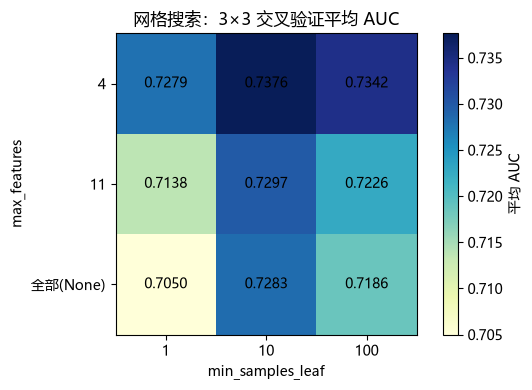

In [4]:
pivot = res_grid.pivot(
    index="param_max_features",
    columns="param_min_samples_leaf",
    values="mean_test_score",
).reindex([4, 11, None])

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(pivot.values, cmap="YlGnBu")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([str(c) for c in pivot.columns])
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(["4", "11", "全部(None)"])
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("max_features")
ax.set_title("网格搜索：3×3 交叉验证平均 AUC")

for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.4f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="平均 AUC")
plt.tight_layout()
plt.show()


讲义中的网格搜索结果：

- 最优组合：`max_features=4`、`min_samples_leaf=10`，3 折交叉验证平均 AUC = **0.7376**；
- `mean_test_score`：3 折平均 AUC，越高越好；
- `std_test_score`：3 折之间的标准差，越小说明三次打分越接近，结果越稳；
- `mean_fit_time`：每组参数平均训练耗时，用来评估算力开销。


## 7.5 随机搜索 RandomizedSearchCV

网格搜索是提前圈定几个固定档位，把所有组合挨个试完。短板是：想试很大一片范围时，候选值一多，组合数量爆炸，算力扛不住。

随机搜索换个思路：**预算固定只试 9 次**，不去铺满整齐网格，在一大片可选范围里随机抽 9 组搭配去尝。

还是奶茶：

- 网格搜索：甜度只选 4、11、全部，冰量只选 1、10、100，总共 9 个固定搭配；
- 随机搜索：甜度范围放开到 1~18，冰量放开到 1、2、3、5、8……一直到 200，可选搭配几百上千种；
- 但预算只有 9 杯（`n_iter=9`），程序从大范围里随机抽 9 组不同的甜度 + 冰量，每组都用 3 折交叉验证打分。

同样只允许试 9 次：网格搜索只能在很小的区域横平竖直踩点；随机搜索可以撒 9 个点，覆盖更大的参数地图，更容易撞到高分区域。

**缺点**：不会遍历全部组合，有可能漏掉最优解；但预算有限时，性价比远高于网格搜索。

区分两种搜索：

- `GridSearchCV`：穷举给定候选列表的所有组合；
- `RandomizedSearchCV`：在给定范围/分布里，随机抽取 `n_iter` 组组合尝试。


In [5]:
# 1. 定义参数搜索空间（范围比网格搜索大很多）
space = {
    "max_features": list(range(1, 19)),
    "min_samples_leaf": [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 75, 100, 150, 200],
}

# 2. 构建随机搜索对象
rand = RandomizedSearchCV(
    estimator=RandomForestClassifier(n_estimators=150, random_state=0),
    param_distributions=space,
    n_iter=9,
    cv=cv3,
    scoring="roc_auc",
    random_state=0,
    n_jobs=-1,
)

# 3. 随机抽取 9 组参数，逐组用 3 折交叉验证打分
rand.fit(E_train, y_train);


In [6]:
res_rand = pd.DataFrame(rand.cv_results_)[
    ["param_max_features", "param_min_samples_leaf", "mean_test_score"]
]
print(res_rand.sort_values("mean_test_score", ascending=False).round(4).to_string(index=False))
print("最好的组合：", rand.best_params_, "交叉验证 AUC", round(rand.best_score_, 4))


 param_max_features  param_min_samples_leaf  mean_test_score
                  5                      20           0.7410
                  9                      15           0.7330
                  8                       5           0.7306
                 12                       8           0.7297
                 11                      75           0.7254
                 15                       5           0.7235
                  6                     200           0.7230
                 17                       5           0.7227
                 13                       3           0.7188
最好的组合： {'min_samples_leaf': 20, 'max_features': 5} 交叉验证 AUC 0.741


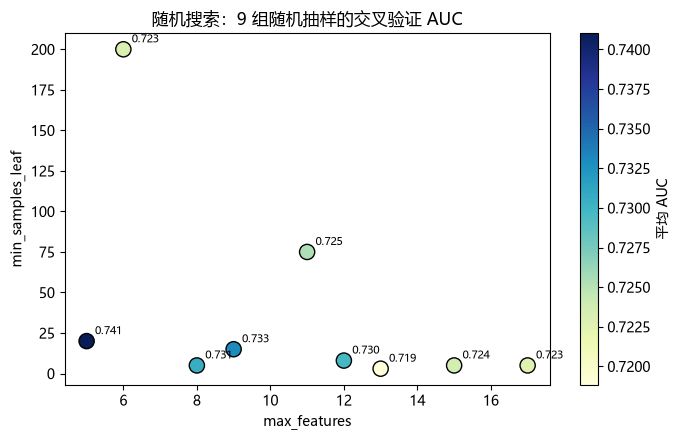

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(
    res_rand["param_max_features"],
    res_rand["param_min_samples_leaf"],
    c=res_rand["mean_test_score"],
    cmap="YlGnBu",
    s=120,
    edgecolor="black",
)
for _, row in res_rand.iterrows():
    ax.annotate(
        f"{row['mean_test_score']:.3f}",
        (row["param_max_features"], row["param_min_samples_leaf"]),
        textcoords="offset points",
        xytext=(6, 5),
        fontsize=8,
    )
ax.set_xlabel("max_features")
ax.set_ylabel("min_samples_leaf")
ax.set_title("随机搜索：9 组随机抽样的交叉验证 AUC")
fig.colorbar(sc, ax=ax, label="平均 AUC")
plt.tight_layout()
plt.show()


### 7.5.3 网格搜索与随机搜索对比

| 对比项 | GridSearchCV 网格搜索 | RandomizedSearchCV 随机搜索 |
|---|---|---|
| 搜索方式 | 给定候选列表，全部组合穷举 | 在大范围里随机抽固定次数（`n_iter`） |
| 同样试 9 次 | 只能在固定 9 个点 | 从巨大参数空间里撒 9 个点，覆盖更广 |
| 优点 | 不漏掉任何给定候选组合，精细 | 相同算力预算下探索范围更大，更容易找到好参数 |
| 缺点 | 参数一多，组合爆炸，速度很慢 | 有概率错过全局最优 |
| 适用场景 | 参数很少、小范围精细调优 | 参数空间大、算力有限，优先用来粗搜 |


## 7.6 最后才使用一次测试集

调参、选模型的时候，绝对不能反复偷看测试集；测试集是期末考试卷子，只能最后考一次。

奶茶店的例子：

- 训练集 + 交叉验证 = 平时练习题 + 随堂小测：网格搜索、随机搜索在练习题上反复试配方，用随堂小测打分，选出最好的甜度、冰量；
- 测试集 = 期末考卷：全程锁起来，调参阶段一眼都不能看。

**错误做法**：调完一组配方，拿期末卷子尝一下分数，再根据期末成绩回头改甜度冰量，反复试。这等于提前偷看期末考试答案，最后分数看着很高，但换到新顾客（全新数据）身上效果会很差。这叫**数据泄露**，也叫**过拟合到测试集**。

**正确流程**：

1. 只靠交叉验证 AUC 选出最优参数（网格/随机搜索自己在训练集内部完成）；
2. `refit=True`：自动拿全部训练数据，把最优配方完整重训一遍；
3. 只在全部参数确定、不再改动任何东西之后，一次性送到测试集上打分；打完就结束，不再回头修改参数。


In [8]:
for name, search in [("网格搜索", grid), ("随机搜索", rand)]:
    best_model = search.best_estimator_
    test_auc = roc_auc_score(y_test, best_model.predict_proba(E_test)[:, 1])
    print(f"{name}: 交叉验证 AUC {search.best_score_:.4f}, 测试集 AUC {test_auc:.4f}")


网格搜索: 交叉验证 AUC 0.7376, 测试集 AUC 0.7560
随机搜索: 交叉验证 AUC 0.7410, 测试集 AUC 0.7547


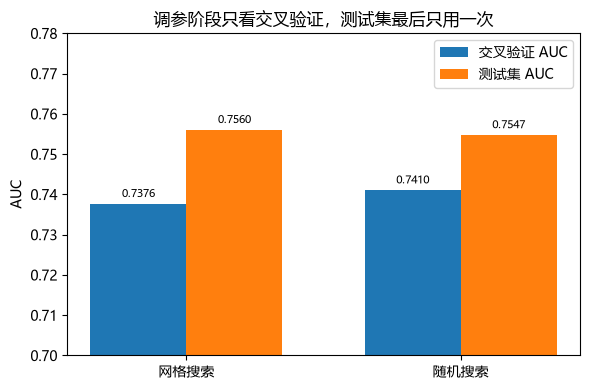

In [9]:
names = ["网格搜索", "随机搜索"]
cv_scores = [grid.best_score_, rand.best_score_]
test_scores = [
    roc_auc_score(y_test, grid.best_estimator_.predict_proba(E_test)[:, 1]),
    roc_auc_score(y_test, rand.best_estimator_.predict_proba(E_test)[:, 1]),
]

x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(6, 4))
b1 = ax.bar(x - width / 2, cv_scores, width, label="交叉验证 AUC")
b2 = ax.bar(x + width / 2, test_scores, width, label="测试集 AUC")

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0.70, 0.78)
ax.set_ylabel("AUC")
ax.set_title("调参阶段只看交叉验证，测试集最后只用一次")
ax.legend()

for bars in (b1, b2):
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.001,
            f"{height:.4f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.tight_layout()
plt.show()


讲义中的结果：

- 网格搜索：3 折交叉验证平均 AUC = **0.7376**；从未参与调参的测试集 AUC = **0.7560**；
- 随机搜索：3 折交叉验证平均 AUC = **0.7410**；测试集 AUC = **0.7547**。

随机搜索的交叉验证分数更高，测试集反而略低一点。交叉验证本身也是抽样，存在随机波动，小幅度差异很正常。规则不变：**选参数时以交叉验证分数为准，不能看测试集反过来选模型**。如果看到测试集 0.756 更高，就回头去选网格搜索，相当于偷看期末成绩选方案，属于典型错误操作。


## 7.7 Optuna 贝叶斯调参

三种搜索的比喻：

- 网格搜索：把山头画成整齐方格，一格一格挨个踩点，不管哪里分数高，顺序固定，盲目；
- 随机搜索：闭着眼随便扔飞镖，这次落点和上次挖到好不好没关系，也是盲目；
- Optuna（TPE 贝叶斯优化）：聪明的寻宝人。挖过几个点后，把高分位置记成“好区域”、低分坑位记成“差区域”，下一次优先去像高分位置、不像低分位置的地方继续挖。

### 7.7.1 TPE 思路

把试出来的结果分成成绩好一堆、成绩差一堆，分别统计分布；下一次挑选**在好堆里很常见、差堆里很少见**的参数组合。

适用场景：模型训练很慢、参数很多、算力很贵时，Optuna 优势巨大；如果参数很少、跑模型一秒钟，三种调参方式差别不大。

### 7.7.2 奶茶配方例子

- 网格：甜度 1~10，冰量 1~10，全部组合挨个试，不管前面哪杯好喝，按顺序试；
- 随机：随便抽甜度冰量，抽到哪个试哪个，和之前好不好喝无关；
- Optuna TPE：先随便试 5 杯，记下评分；把前 5 杯分成“好喝组 top2”和“难喝组剩下 3 个”；统计发现好喝的甜度集中在 5~7、冰量 3~5，难喝的大多甜度 >8 或 <2；下一杯优先去甜度 5~7、冰量 3~5 附近挑组合，不去明显踩坑区间；试 30 次，同样试验次数下更容易找到高分配方。

两个企业实用特性：

1. **剪枝 pruning**：一杯奶茶刚泡一半，尝一口发现明显翻车，直接倒掉不做完，节省原料（算力）；
2. **持久化 storage**：把试了 10 次的记录保存到数据库，电脑关机重启后可以接着上次的记录继续试，甚至多个人一起试同一个配方任务。

使用前安装：

```bash
pip install optuna
```

注意：Optuna 的 `objective` 函数里只用交叉验证打分，全程不碰测试集；等 `study` 选出 `best_params` 后，再拿它构建模型、refit 全训练集，最后只跑一次测试集评估泛化。


In [10]:
import optuna

# 减少 Optuna 的训练日志刷屏
optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial):
    # Optuna 每一轮试验都会调用这个函数
    params = {
        "max_features": trial.suggest_int("max_features", 1, 18),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 200, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=50),
    }
    model = RandomForestClassifier(random_state=0, n_jobs=-1, **params)
    return cross_val_score(
        model, E_train, y_train, cv=cv3, scoring="roc_auc"
    ).mean()


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=0),
)
study.optimize(objective, n_trials=30)


In [11]:
print("最优参数：", study.best_params, "最优交叉验证 AUC：", round(study.best_value, 4))
print(
    study.trials_dataframe()[
        ["number", "value", "params_max_features", "params_min_samples_leaf"]
    ].to_string(index=False)
)


最优参数： {'max_features': 3, 'min_samples_leaf': 23, 'n_estimators': 150} 最优交叉验证 AUC： 0.7445
 number    value  params_max_features  params_min_samples_leaf
      0 0.733759                   10                       36
      1 0.730418                   10                        6
      2 0.726548                    8                      105
      3 0.734664                    7                       58
      4 0.720817                   11                      128
      5 0.717742                    2                        1
      6 0.721448                   15                       92
      7 0.726529                   15                        8
      8 0.744462                    3                       23
      9 0.727660                   18                       11
     10 0.725549                    1                        8
     11 0.734369                    4                       82
     12 0.734747                    6                       12
     13 0.730053            

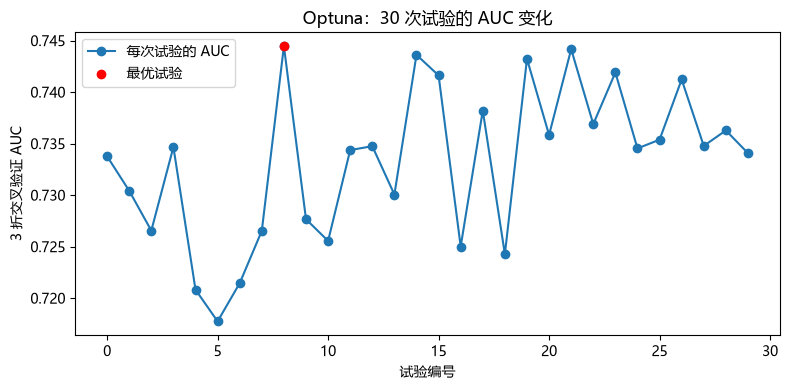

In [12]:
trials = study.trials_dataframe()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trials["number"], trials["value"], marker="o", label="每次试验的 AUC")
best_idx = trials["value"].idxmax()
ax.scatter(
    trials.loc[best_idx, "number"],
    trials.loc[best_idx, "value"],
    color="red",
    zorder=5,
    label="最优试验",
)
ax.set_xlabel("试验编号")
ax.set_ylabel("3 折交叉验证 AUC")
ax.set_title("Optuna：30 次试验的 AUC 变化")
ax.legend()
plt.tight_layout()
plt.show()


### 7.7.3 三种搜索的对比

| 方式 | 思路 | 特点 |
|---|---|---|
| 网格搜索 | 把参数空间均匀布点，挨个试 | 简单；参数一多，爆炸，慢 |
| 随机搜索 | 在范围里随机采样，互不相关 | 比网格高效一点，依然盲目 |
| Optuna TPE 贝叶斯 | 利用历史结果，学习好坏区域，下一次优先去高分可能性高的地方 | 昂贵模型、参数多的时候省算力；聪明，有记忆 |


## 7.8 把搜索过程记进 MLflow

奶茶配方实验：

- **父运行**：整一次配方试验任务。记录这次用的是随机搜索、一共试 9 杯、3 个评委打分、固定用 150ml 红茶底、实验负责人、最后最好喝的那一杯分数和配方。相当于实验记录本的封面。
- **子运行**（`nested=True`）：每一杯单独试的奶茶。每一杯单独开一页记录，记下甜度、冰量、平均分、分数波动。相当于记录本里每一页的单条记录。

为什么要父子结构，而不是全部平铺？

1. 一眼看总任务：这次调参方法、预算、最优结果；
2. 点开父运行，可以展开看到全部 9 次子试验；
3. MLflow 界面自带功能：对子运行按 AUC 排序、画平行坐标图，直观看到哪些参数更容易出高分；
4. 对比：`autolog()` 自动记录省事，但记录哪些内容不由我们控制；正式项目手写嵌套 run，想记什么、不想记什么完全自己掌控，更清晰可控。

`mlflow.sklearn.autolog()` 对 `GridSearchCV` 可以自动生成父子 run，`max_tuning_runs` 控制最多记录多少个子试验；适合快速 demo；工业项目手写嵌套 run 更可控。

**重点**：`nested=True` 是嵌套标记。不加这个标记，新的 `start_run` 会把上一个 run 直接结束，没法形成父子关系。

讲义中实验名写作 `credit-rish-rf`，这里按正确拼写使用 `credit-risk-rf`。


In [13]:
import os
import mlflow

# 优先读取环境变量；没有配置时，存到当前目录的 SQLite 数据库
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "sqlite:///mlflow.db"))
mlflow.set_experiment("credit-risk-rf")

res = rand.cv_results_

with mlflow.start_run(run_name="random-search"):
    mlflow.set_tags({
        "owner": "laoma",
        "purpose": "随机搜索 max_features 和 min_samples_leaf",
    })
    mlflow.log_params({
        "method": "random",
        "n_iter": 9,
        "cv": 3,
        "n_estimators": 150,
    })

    for i, params in enumerate(res["params"]):
        with mlflow.start_run(run_name=f"trial-{i + 1}", nested=True):
            mlflow.log_params(params)
            mlflow.log_metrics({
                "cv_auc": res["mean_test_score"][i],
                "cv_auc_std": res["std_test_score"][i],
            })

    mlflow.log_params({f"best_{k}": v for k, v in rand.best_params_.items()})
    mlflow.log_metric("best_cv_auc", rand.best_score_)
    mlflow.sklearn.log_model(
        rand.best_estimator_,
        name="model",
        serialization_format="cloudpickle",
    )


2026/11/09 18:05:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


### 7.8.1 在 MLflow UI 中查看

运行上面的单元格后，`notebooks/` 下会生成 `mlflow.db` 和 `mlruns/`。在 `notebooks/` 目录启动：

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

浏览器访问 <http://127.0.0.1:5000>。

在 `credit-risk-rf` 实验里：

- 父运行 `random-search`：记录调参方法、预算、交叉验证折数、固定参数，以及 `best_*`、`best_cv_auc` 和模型 `model`；
- 子运行 `trial-1` … `trial-9`：每个子运行记录当组参数、`cv_auc`、`cv_auc_std`；
- 点开父运行，可以折叠展开全部子试验；对子运行按 AUC 排序、画平行坐标图。


## 7.9 调参规则

1. **测试集只用一次**：挑参数用交叉验证或袋外估计；定下来以后，在测试集上确认一次，报告这个数。要严格估计“调参 + 训练”整个流程的泛化能力，可以用嵌套交叉验证：外层做评估，内层做搜索。
2. **先定预算，再定空间**：预算是“最多试几次”或“最多跑多久”；空间要覆盖合理范围；像叶子大小、学习率这类跨好几个数量级的参数，在对数尺度上取值；最好的值如果落在空间边上，把空间往外扩一圈再搜。
3. **比不出高下时，按成本和可解释性选**：交叉验证成绩只差 0.003，这一轮结果不足以说明哪组更好，也不能反过来断定“只是随机波动”；这时选更简单、更快、更小的那组参数（比如叶子更大的森林）。真要比较这么小的差别，看同样几折上的逐折差（配对比较），或者换几次划分重复做。折间标准差、置换重要性的重复标准差、平均值的标准误是三个不同的量，不能互相代替。
4. **一切可复现**：固定所有随机种子（划分、交叉验证、模型、搜索）；搜索空间写进配置文件并提交到 Git；每一次尝试记进 MLflow。三个月后有人问“为什么选这组参数”，打开 MLflow 就能回答。
5. **算一算成本**：调参的算力是真金白银。先用少量的树、较小的数据快速粗搜，锁定大致区域后再细搜；`n_jobs` 用上多核；能用袋外估计时，不必每次都做交叉验证。


## 本章小结

- 调参不是碰运气，而是可复现的流程：先定搜索空间和预算，用交叉验证当裁判，记录每一次尝试。
- 网格搜索适合参数少、候选值少的小范围精细搜索；随机搜索适合预算有限、参数空间大的粗搜；Optuna TPE 会利用历史结果，适合训练慢、参数多、算力贵的场景。
- 不管用哪种方法，测试集只在最后用一次；调参阶段只看交叉验证或袋外估计。
- 用 MLflow 的父子运行记录整个搜索过程：父运行记录任务级信息，子运行记录每一组参数和分数。
